# 04 - Pitch keypoints, homography and minimap

Pipeline: YOLO26s-pose pitch keypoints (32 points) -> per-frame homography (RANSAC) -> projection of player and ball positions onto a 2D pitch.

Dataset: [football-field-detection-f07vi v18](https://universe.roboflow.com/roboflow-jvuqo/football-field-detection-f07vi) by Roboflow (CC BY 4.0), 960x960 images.

Inputs on Google Drive (`football-analytics/`): a test video in `videos/input/` and the outputs of notebook 03 (`tracks_teams.csv`, `ball_track.csv`) in `videos/output/<clip>_botsort/`.

## 1. Setup

In [5]:
!nvidia-smi
!pip install -q ultralytics==8.4.174 roboflow

Fri Oct 16 01:41:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from ultralytics import YOLO

drive.mount("/content/drive")

base = Path("/content/drive/MyDrive/football-analytics")
CLIP = "clip01.mp4"
src = base / "videos/input" / CLIP
out = base / "videos/output" / f"{src.stem}_botsort"
weights = base / "runs/pitch_yolo26s_pose_960/weights/best.pt"
assert src.exists(), f"missing video: {src}"
assert (out / "tracks_teams.csv").exists(), "run notebook 03 first"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive


## 2. Dataset

In [7]:
from getpass import getpass

from roboflow import Roboflow

rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("roboflow-jvuqo").project("football-field-detection-f07vi")
project.version(18).download("yolov8", location="/content/data/pitch")

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/data/pitch in yolov8:: 100%|██████████| 639/639 [00:00<00:00, 6019.32it/s]


## 3. Training (skipped if the weights already exist)

In [8]:
if weights.exists():
    print("weights found, skipping training:", weights)
else:
    YOLO("yolo26s-pose.pt").train(
        data="/content/data/pitch/data.yaml",
        epochs=100,
        imgsz=960,
        batch=8,
        seed=0,
        workers=2,
        project=str(base / "runs"),
        name="pitch_yolo26s_pose_960",
    )
assert weights.exists()

weights found, skipping training: /content/drive/MyDrive/football-analytics/runs/pitch_yolo26s_pose_960/weights/best.pt


## 4. Pitch layout (32 keypoints, meters) and layout check on ground-truth labels

In [9]:
L, W = 105.0, 68.0
PB_W, PB_L, GB_W, GB_L, SPOT, R = 40.32, 16.5, 18.32, 5.5, 11.0, 9.15

PITCH = np.array([
    (0, 0), (0, (W - PB_W) / 2), (0, (W - GB_W) / 2), (0, (W + GB_W) / 2), (0, (W + PB_W) / 2), (0, W),
    (GB_L, (W - GB_W) / 2), (GB_L, (W + GB_W) / 2),
    (SPOT, W / 2),
    (PB_L, (W - PB_W) / 2), (PB_L, (W - GB_W) / 2), (PB_L, (W + GB_W) / 2), (PB_L, (W + PB_W) / 2),
    (L / 2, 0), (L / 2, W / 2 - R), (L / 2, W / 2 + R), (L / 2, W),
    (L - PB_L, (W - PB_W) / 2), (L - PB_L, (W - GB_W) / 2), (L - PB_L, (W + GB_W) / 2), (L - PB_L, (W + PB_W) / 2),
    (L - SPOT, W / 2),
    (L - GB_L, (W - GB_W) / 2), (L - GB_L, (W + GB_W) / 2),
    (L, 0), (L, (W - PB_W) / 2), (L, (W - GB_W) / 2), (L, (W + GB_W) / 2), (L, (W + PB_W) / 2), (L, W),
    (L / 2 - R, W / 2), (L / 2 + R, W / 2),
], dtype=np.float32)

t = np.linspace(0, 2 * np.pi, 60)
LINES = [
    [(0, 0), (L, 0), (L, W), (0, W), (0, 0)],
    [(L / 2, 0), (L / 2, W)],
    [(0, (W - PB_W) / 2), (PB_L, (W - PB_W) / 2), (PB_L, (W + PB_W) / 2), (0, (W + PB_W) / 2)],
    [(L, (W - PB_W) / 2), (L - PB_L, (W - PB_W) / 2), (L - PB_L, (W + PB_W) / 2), (L, (W + PB_W) / 2)],
    [(0, (W - GB_W) / 2), (GB_L, (W - GB_W) / 2), (GB_L, (W + GB_W) / 2), (0, (W + GB_W) / 2)],
    [(L, (W - GB_W) / 2), (L - GB_L, (W - GB_W) / 2), (L - GB_L, (W + GB_W) / 2), (L, (W + GB_W) / 2)],
    list(zip(L / 2 + R * np.cos(t), W / 2 + R * np.sin(t))),
]

valid images with homography: 34 / 34
inlier ratio median: 0.86 | median error (px): 1.5


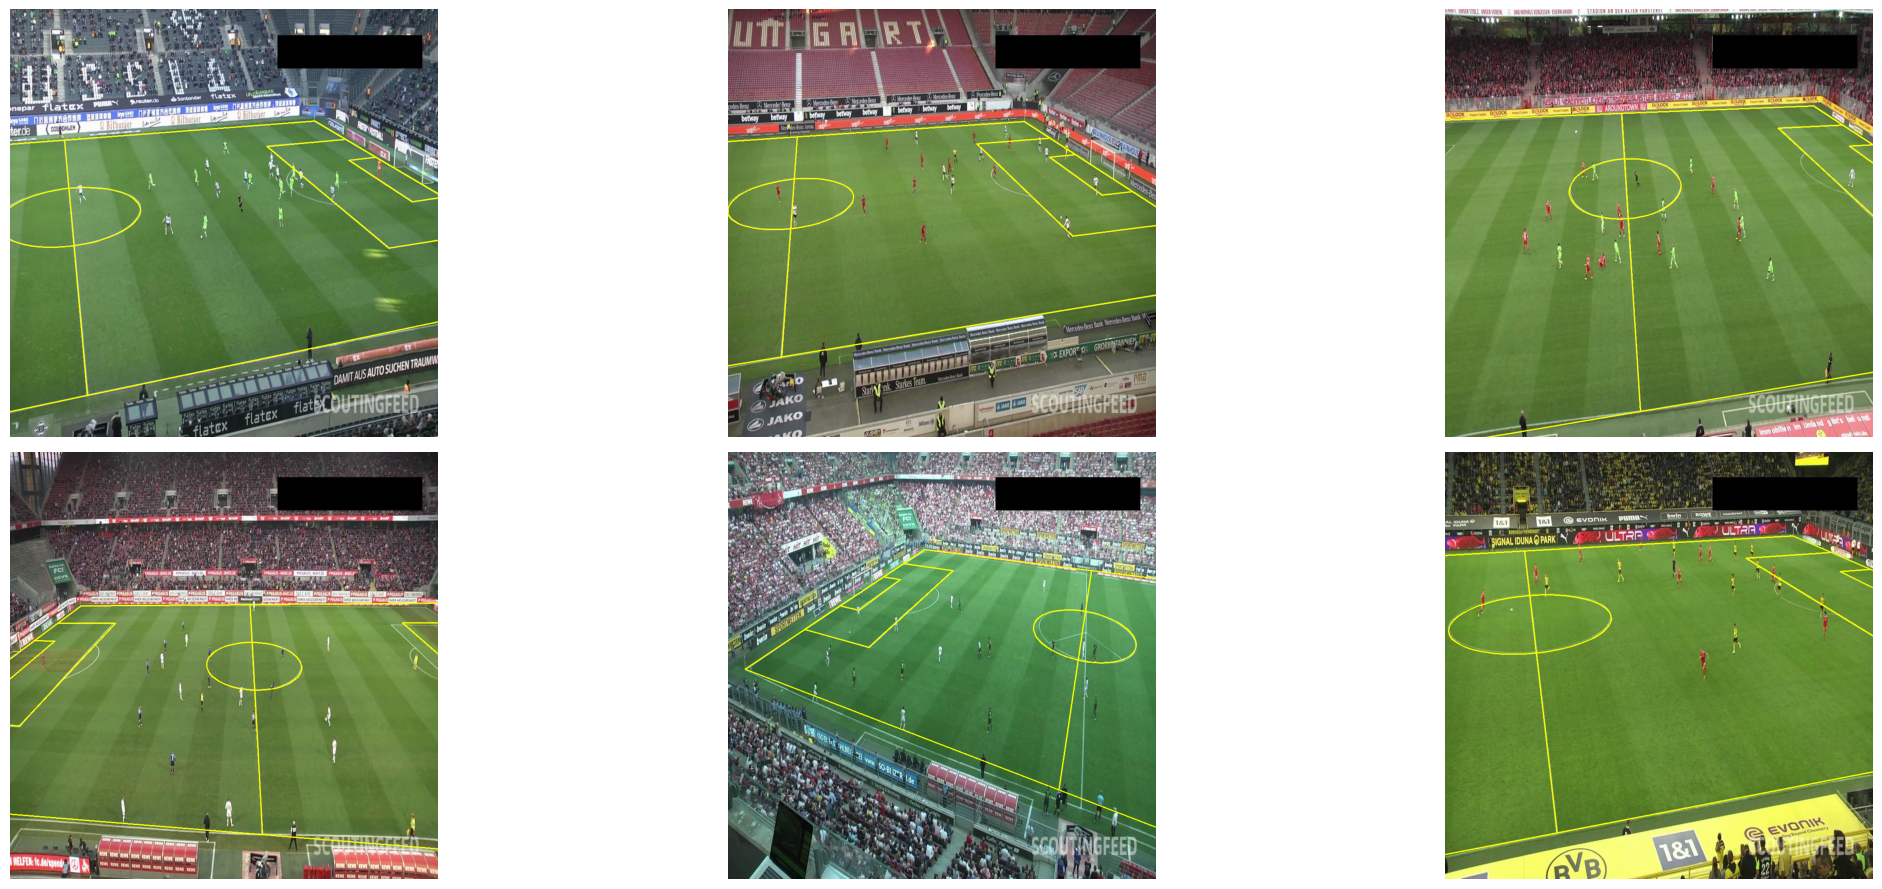

In [10]:
droot = Path("/content/data/pitch")
imgs = sorted((droot / "valid" / "images").glob("*"))

rows, shown = [], []
for p in imgs:
    img = cv2.imread(str(p))
    h, w = img.shape[:2]
    vals = np.array((droot / "valid" / "labels" / (p.stem + ".txt")).read_text().splitlines()[0].split(), dtype=float)
    kp = vals[5:].reshape(-1, 3)
    idx = np.where(kp[:, 2] > 0)[0]
    if len(idx) < 4:
        continue
    image = (kp[idx, :2] * [w, h]).astype(np.float32)
    world = PITCH[idx]
    H, mask = cv2.findHomography(world, image, cv2.RANSAC, 8.0)
    if H is None:
        continue
    err = np.linalg.norm(cv2.perspectiveTransform(world[None], H)[0] - image, axis=1)
    rows.append({"n": len(idx), "inliers": int(mask.sum()), "err_median": float(np.median(err))})
    shown.append((img, H))

ge = pd.DataFrame(rows)
print("valid images with homography:", len(ge), "/", len(imgs))
print("inlier ratio median:", round(float((ge.inliers / ge.n).median()), 2), "| median error (px):", round(float(ge.err_median.median()), 1))

fig, axes = plt.subplots(2, 3, figsize=(24, 9))
for ax, (img, H) in zip(axes.ravel(), shown[:: max(1, len(shown) // 6)][:6]):
    for line in LINES:
        pts = cv2.perspectiveTransform(np.array(line, np.float32)[None], H)[0]
        cv2.polylines(img, [np.clip(pts, -20000, 20000).astype(np.int32)], False, (0, 255, 255), 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()

## 5. Keypoints on the test video (frames resized to 960x960, as in training)

In [11]:
pitch_model = YOLO(weights)

cap = cv2.VideoCapture(str(src))
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W_IMG, H_IMG = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()


def keypoints_stretched(batch_size=16):
    rows, frames, ids = [], [], []

    def flush():
        for f, r in zip(ids, pitch_model.predict(frames, imgsz=960, conf=0.05, verbose=False)):
            if r.keypoints is None or len(r.boxes) == 0:
                continue
            j = int(r.boxes.conf.argmax())
            xy = r.keypoints.xy[j].cpu().numpy() * [W_IMG / 960, H_IMG / 960]
            cf = r.keypoints.conf[j].cpu().numpy()
            rows.extend({"frame": f, "kp": k, "x": float(xy[k, 0]), "y": float(xy[k, 1]), "conf": float(cf[k])} for k in range(len(xy)))
        frames.clear()
        ids.clear()

    cap = cv2.VideoCapture(str(src))
    f = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(cv2.resize(frame, (960, 960)))
        ids.append(f)
        f += 1
        if len(frames) == batch_size:
            flush()
    if frames:
        flush()
    cap.release()
    return pd.DataFrame(rows)


kps = keypoints_stretched()
kps.to_csv(out / "pitch_keypoints.csv", index=False)
print("frames with a pitch detection:", kps.frame.nunique(), "/", n_frames)

frames with a pitch detection: 922 / 922


## 6. Homography per frame (RANSAC, front-line points excluded)

frames with a homography: 900 / 922 | points median=7 | inlier ratio median=0.75


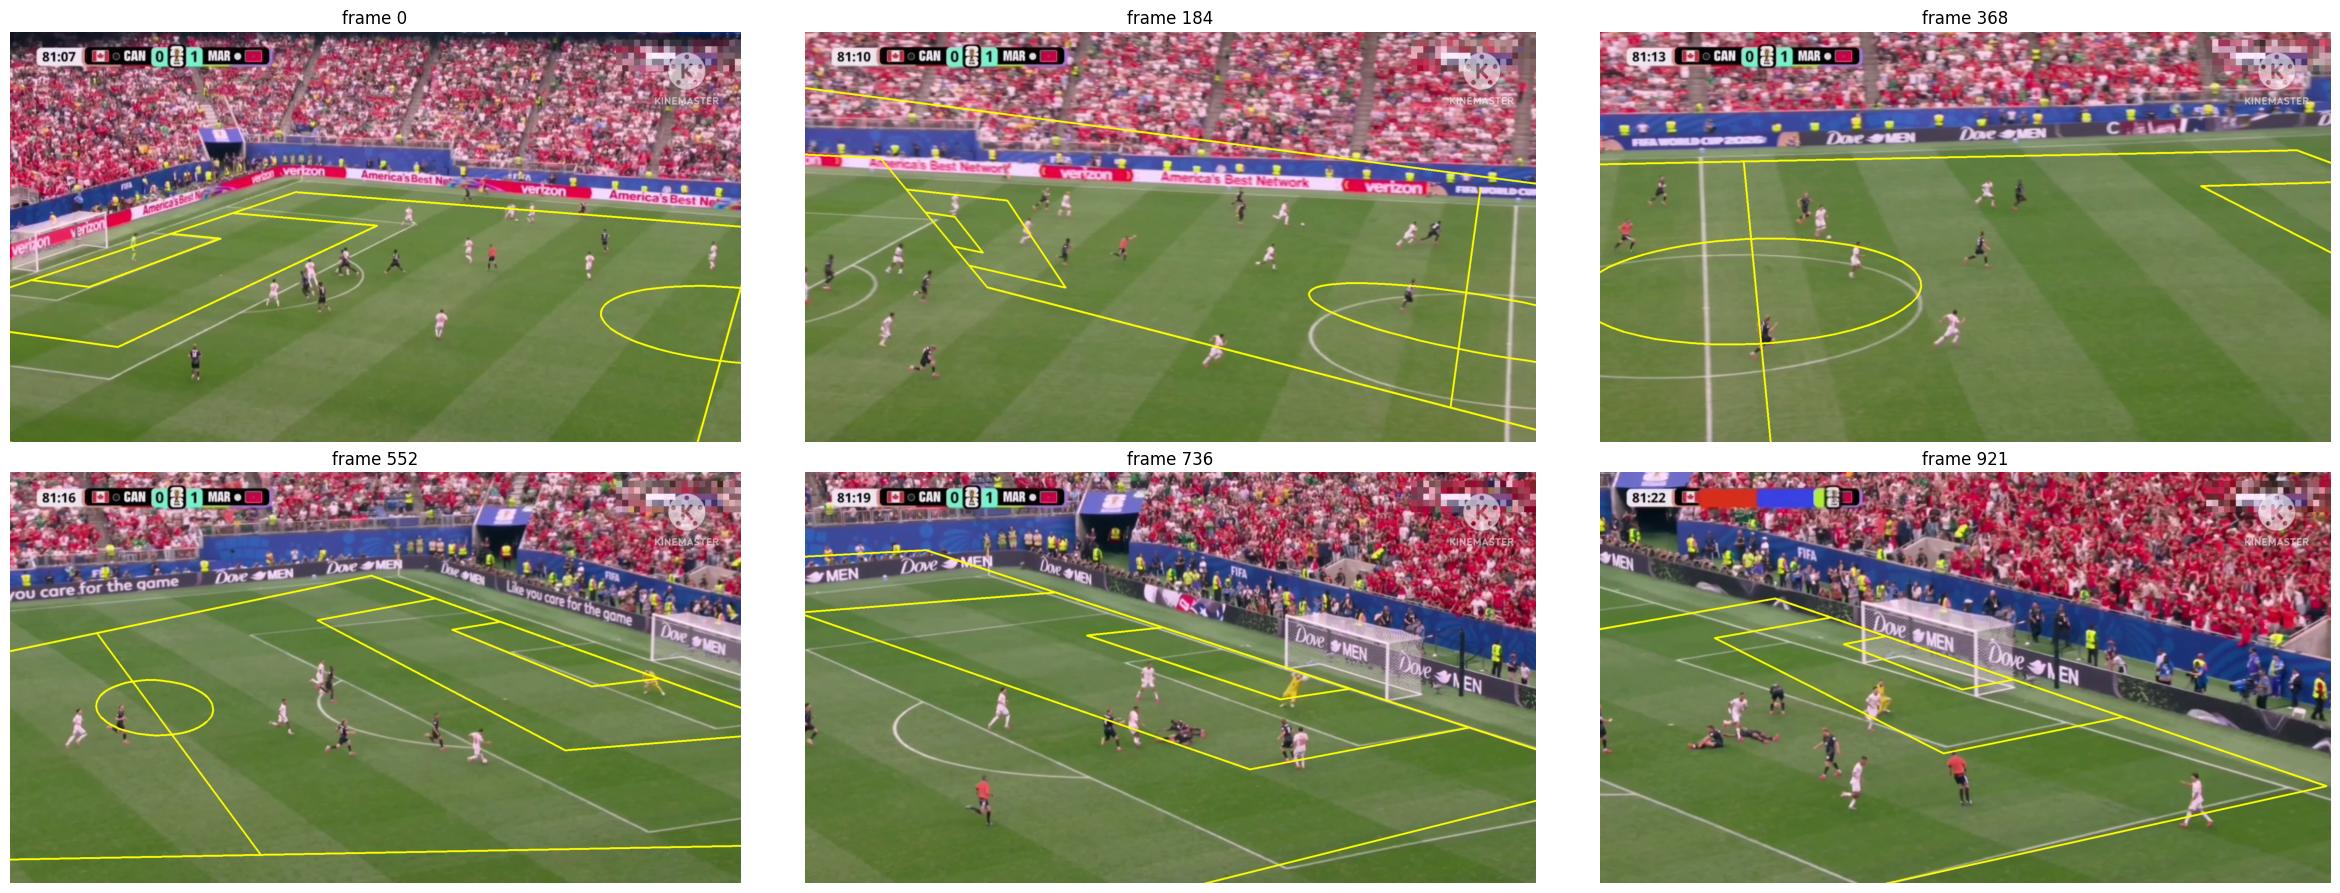

In [12]:
KP_CONF, MARGIN, REPROJ_PX = 0.5, 10, 8.0
BAD = [3, 9, 10, 11, 12, 17, 18, 19, 20, 28]


def fit_homographies(df, exclude=BAD, thr=REPROJ_PX):
    Hs, rows = {}, []
    for f, g in df.groupby("frame"):
        g = g[(g.conf >= KP_CONF) & g.x.between(MARGIN, W_IMG - MARGIN) & g.y.between(MARGIN, H_IMG - MARGIN) & ~g.kp.isin(exclude)]
        if len(g) < 4:
            continue
        world = PITCH[g.kp.to_numpy()]
        image = g[["x", "y"]].to_numpy(np.float32)
        H, mask = cv2.findHomography(world, image, cv2.RANSAC, thr)
        if H is None:
            continue
        Hs[f] = H
        rows.append({"frame": f, "n": len(g), "inliers": int(mask.sum())})
    return Hs, pd.DataFrame(rows)


Hs, st = fit_homographies(kps)
np.savez(out / "homographies.npz", frames=np.array(list(Hs)), H=np.stack(list(Hs.values())))
print(f"frames with a homography: {len(st)} / {n_frames} | points median={int(st.n.median())} | inlier ratio median={(st.inliers / st.n).median():.2f}")

cap = cv2.VideoCapture(str(src))
fig, axes = plt.subplots(2, 3, figsize=(24, 9))
for ax, f in zip(axes.ravel(), np.linspace(0, n_frames - 1, 6).astype(int)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(f))
    ok, frame = cap.read()
    if f in Hs:
        for line in LINES:
            pts = cv2.perspectiveTransform(np.array(line, np.float32)[None], Hs[f])[0]
            cv2.polylines(frame, [np.clip(pts, -20000, 20000).astype(np.int32)], False, (0, 255, 255), 3)
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {f}" + ("" if f in Hs else " - no homography"))
    ax.axis("off")
cap.release()
plt.tight_layout()

## 7. Minimap (no video frames, only 2D positions)

In [13]:
tt = pd.read_csv(out / "tracks_teams.csv")
traj = pd.read_csv(out / "ball_track.csv", index_col=0)
traj["ok"] = traj.cx.notna() & ~traj.interpolated.astype(bool) & (traj.conf >= 0.25)

valid = np.array(sorted(Hs))


def H_for(f, max_gap=10):
    if f in Hs:
        return Hs[f]
    prev = valid[valid < f]
    if len(prev) and f - prev[-1] <= max_gap:
        return Hs[prev[-1]]
    return None


pts = []
for r in tt.itertuples():
    H = H_for(r.frame)
    if H is None:
        continue
    foot = np.array([[[(r.x1 + r.x2) / 2, r.y2]]], np.float32)
    X, Y = cv2.perspectiveTransform(foot, np.linalg.inv(H))[0, 0]
    pts.append((r.frame, r.track_id, r.cls_smooth, r.team, X, Y))

proj = pd.DataFrame(pts, columns=["frame", "track_id", "cls", "team", "X", "Y"])
proj = proj[proj.X.between(-5, L + 5) & proj.Y.between(-5, W + 5)].sort_values(["track_id", "frame"])
for c in ("X", "Y"):
    proj[c] = proj.groupby("track_id")[c].transform(lambda s: s.rolling(5, center=True, min_periods=1).median())
proj.to_csv(out / "minimap_positions.csv", index=False)
print("detections:", len(tt), "| projected inside the pitch:", len(proj))

detections: 12077 | projected inside the pitch: 11368


In [14]:
S, PAD = 8, 20


def to_px(x, y):
    return int(PAD + x * S), int(PAD + y * S)


pitch_img = np.full((int(W * S) + 2 * PAD, int(L * S) + 2 * PAD, 3), (40, 110, 40), np.uint8)
for line in LINES:
    cv2.polylines(pitch_img, [np.array([to_px(x, y) for x, y in line], np.int32)], False, (255, 255, 255), 2)
ph, pw = pitch_img.shape[:2]

raw_path = out / f"{src.stem}_minimap_only_raw.mp4"
writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (pw, ph))

by_f = {f: g for f, g in proj.groupby("frame")}
ball_drawn = 0
for i in range(n_frames):
    mm = pitch_img.copy()
    H = H_for(i)
    g = by_f.get(i)
    if g is not None:
        for r in g.itertuples():
            color = (0, 255, 255) if r.cls == 3 else (0, 0, 255) if r.team == 0 else (255, 120, 0) if r.team == 1 else (160, 160, 160)
            cv2.circle(mm, to_px(r.X, r.Y), 7, color, -1)
            cv2.circle(mm, to_px(r.X, r.Y), 7, (255, 255, 255), 1)
    if H is not None and traj.ok.get(i, False):
        bx, by = cv2.perspectiveTransform(np.array([[[traj.at[i, "cx"], traj.at[i, "cy"]]]], np.float32), np.linalg.inv(H))[0, 0]
        if -5 <= bx <= L + 5 and -5 <= by <= W + 5:
            cv2.circle(mm, to_px(bx, by), 5, (255, 0, 255), -1)
            ball_drawn += 1
    writer.write(mm)
writer.release()
print("frames with a ball on the minimap:", ball_drawn, "/", n_frames)

final_path = out / f"{src.stem}_minimap_only.mp4"
gif_path = out / f"{src.stem}_minimap_only.gif"
!ffmpeg -y -loglevel error -i "{raw_path}" -c:v libx264 -crf 23 -pix_fmt yuv420p "{final_path}"
!ffmpeg -y -loglevel error -i "{final_path}" -vf "fps=12,scale=720:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse" "{gif_path}"
!ls -lh "{out}" | grep minimap_only

frames with a ball on the minimap: 545 / 922
-rw------- 1 root root 1.9M Oct 16 01:45 clip01_minimap_only.gif
-rw------- 1 root root 378K Oct 16 01:44 clip01_minimap_only.mp4
-rw------- 1 root root 4.6M Oct 16 01:44 clip01_minimap_only_raw.mp4
